In [1]:
import sys

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Time tags for ERA5 files ...
201501
2015010100_2015010105


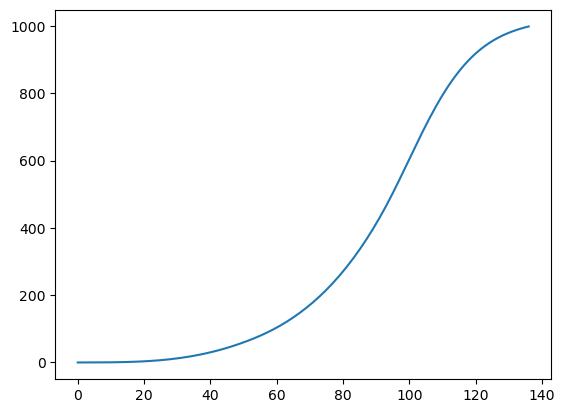

In [2]:
era5dir = "/glade/campaign/collections/rda/data/ds633.6/e5.oper.an.ml/"

year, month, day, hour0 = 2015,1,1,0
monStr=str( year ).zfill(4)+str(month).zfill(2)
# CAM history style yyyy-mm-dd string
ymdStr=str( year ).zfill(4) + '-' + str(month).zfill(2) + '-' + str(day).zfill(2)

hour1=hour0+5
ymdh0=str( year ).zfill(4)+str(month).zfill(2)+str(day).zfill(2)+str(hour0).zfill(2)
ymdh1=str( year ).zfill(4)+str(month).zfill(2)+str(day).zfill(2)+str(hour1).zfill(2)
ymdh=ymdh0+'_'+ymdh1
    
print( "Time tags for ERA5 files ...")
print(monStr)
print(ymdh) 


wrkdir=era5dir+monStr+"/"
#Define all file names for later use in dask function
#-----------------------------------------------------
spfile= wrkdir + 'e5.oper.an.ml.128_134_sp.regn320sc.'+ymdh+'.nc'
tfile = wrkdir + 'e5.oper.an.ml.0_5_0_0_0_t.regn320sc.'+ymdh+'.nc'
New=xr.open_dataset(tfile ,  decode_times=False )


hyai = New.a_half.values/100_000.
hybi = New.b_half.values
hyam = New.a_model.values/100_000.
hybm = New.b_model.values

lev  = (hyam+hybm) * 1_000.
ilev  = (hyai+hybi) * 1_000.
plt.plot(lev) 

In [3]:
dims   = ["lev","ilev"]
coords = dict( 
    lev  = ( ["lev"],lev),
    ilev = ( ["ilev"],ilev),
)

NewVgrid = xr.Dataset( coords=coords  )

Dar = xr.DataArray( data=hyai, dims=('ilev',),
                    attrs=dict( description='interface hybrid eta coordinate A-coeff ',units='1',) ,) 
NewVgrid['hyai'] = Dar

Dar = xr.DataArray( data=hybi, dims=('ilev',),
                    attrs=dict( description='interface hybrid eta coordinate B-coeff ',units='1',) ,) 
NewVgrid['hybi'] = Dar

Dar = xr.DataArray( data=hyam, dims=('lev',),
                    attrs=dict( description='mid-level hybrid eta coordinate A-coeff ',units='1',) ,) 
NewVgrid['hyam'] = Dar

Dar = xr.DataArray( data=hybm, dims=('lev',),
                    attrs=dict( description='mid-level hybrid eta coordinate B-coeff ',units='1',) ,) 
NewVgrid['hybm'] = Dar

myGridFiles = '/glade/work/juliob/GridFiles/'

NewVgridFile = f'{myGridFiles}/Vertical/GRID_137L_ERA5.nc'
NewVgrid.to_netcdf( NewVgridFile )


#